# Lab 03: Dự đoán chuỗi thời gian bằng Machine Learning (XGBoost)

**Dataset:** PJM Hourly Energy Consumption, file `AEP_hourly.csv` (cột `AEP_MW`, đơn vị Megawatt) · **Thư viện:** `pandas`, `xgboost`, `scikit-learn`, `matplotlib`

**Ý tưởng:** chuyển chuỗi thời gian thành bài toán học có giám sát: dùng `k` giá trị quá khứ (`lag_1 … lag_k`) để dự đoán giá trị tại thời điểm kế tiếp.

**Quy tắc áp dụng (kế thừa từ Lab 02):**
- Chia Train/Test **theo thời gian**, không shuffle; mô hình chỉ `fit` trên Train, Test chỉ dùng ở bước dự đoán và đánh giá.
- Mọi đặc trưng tại thời điểm `t` chỉ được dùng dữ liệu đến `t-1` (chống rò rỉ dữ liệu), kể cả rolling mean/std.
- Báo cáo đủ MAE, RMSE, MAPE (thêm R²); mọi hàm tự định nghĩa nằm trong `src/lab03_utils/` và có docstring 3 ý.

In [1]:
import sys, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.lab03_utils.features import (load_energy_series, make_lag_features, add_rolling_features,
                                      split_X_y, time_train_test_split, make_multistep_targets)
from src.lab03_utils.modeling import (train_xgboost, train_linear_regression, train_random_forest,
                                      evaluate_regression, get_feature_importance, plot_feature_importance,
                                      plot_prediction, recursive_forecast, train_direct_models,
                                      direct_forecast, multistep_metrics_by_horizon, tune_xgboost_timeseries)

fig_dir = project_root / 'reports' / 'figures' / 'lab03'
processed_dir = project_root / 'data' / 'processed' / 'lab03'
fig_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
N_LAGS = 24   # k = 24 giờ = 1 chu kỳ ngày

## Bước 1: Chuẩn bị dữ liệu

Số dòng file gốc: 121273 | timestamp trùng: 4 | file đã sắp xếp theo thời gian: False
Sau làm sạch: 121296 giờ, 2004-10-01 01:00:00 → 2018-08-03 00:00:00 | NaN: 0
Số giờ được thêm lại: 27


count    121296.0
mean      15499.2
std        2591.4
min        9581.0
25%       13629.0
50%       15309.0
75%       17200.0
max       25695.0
Name: AEP_MW, dtype: float64

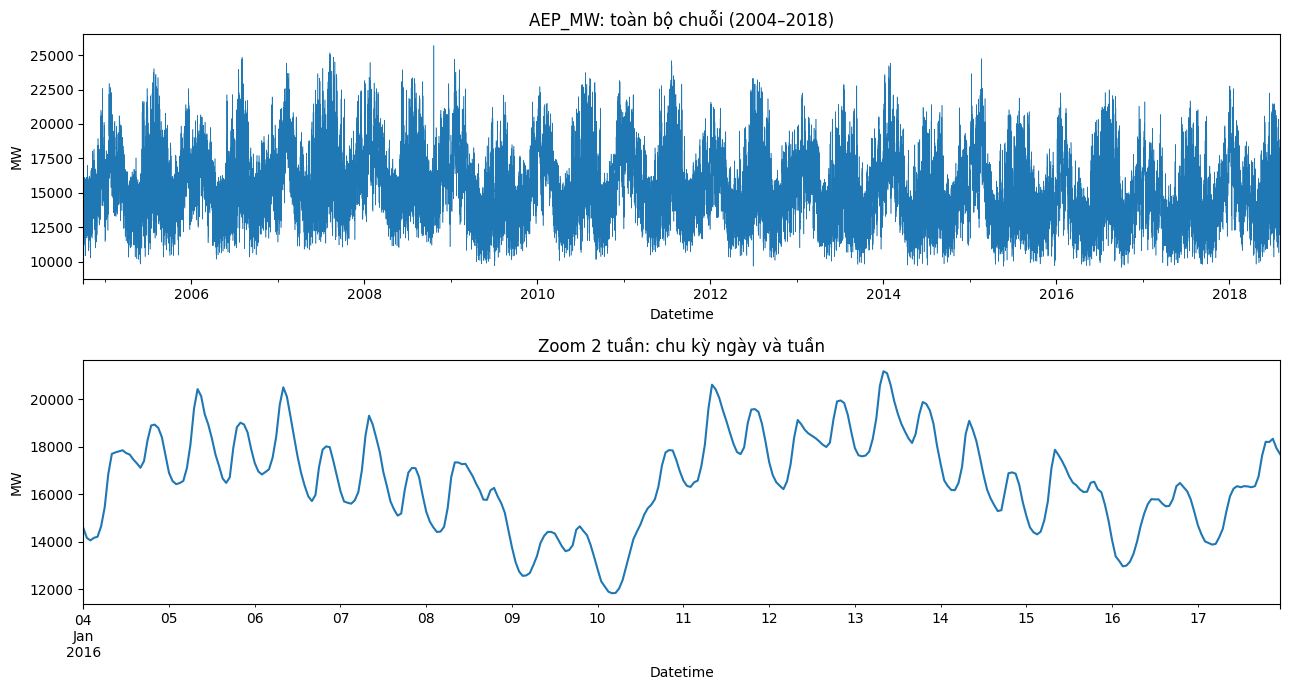

In [2]:
raw = pd.read_csv(project_root / 'data' / 'raw' / 'AEP_hourly.csv', parse_dates=['Datetime'])
print('Số dòng file gốc:', len(raw), '| timestamp trùng:', raw['Datetime'].duplicated().sum(),
      '| file đã sắp xếp theo thời gian:', raw['Datetime'].is_monotonic_increasing)

series = load_energy_series(str(project_root / 'data' / 'raw' / 'AEP_hourly.csv'))
print('Sau làm sạch:', len(series), 'giờ,', series.index.min(), '→', series.index.max(), '| NaN:', series.isna().sum())
print('Số giờ được thêm lại:', len(series) - raw['Datetime'].nunique())
display(series.describe().round(1))

fig, ax = plt.subplots(2, 1, figsize=(13, 7))
series.plot(ax=ax[0], lw=0.4, color='tab:blue'); ax[0].set_title('AEP_MW: toàn bộ chuỗi (2004–2018)'); ax[0].set_ylabel('MW')
series['2016-01-04':'2016-01-17'].plot(ax=ax[1], color='tab:blue'); ax[1].set_title('Zoom 2 tuần: chu kỳ ngày và tuần'); ax[1].set_ylabel('MW')
plt.tight_layout(); plt.savefig(fig_dir / 'step1_series.png', dpi=120, bbox_inches='tight'); plt.show()

**Nhận xét Bước 1:** **Nhận xét Bước 1:**
- File gốc có 121,273 dòng, **chưa sắp xếp theo thời gian** và có 4 timestamp trùng (giờ lùi đồng hồ DST). Sau khi sắp xếp, bỏ trùng và thêm lại các giờ thiếu rồi nội suy (tối đa 3 giờ liên tiếp), chuỗi có **121,296 giờ** liên tục từ 01/10/2004 đến 03/08/2018, không còn NaN (27 giờ được thêm lại).
- Chuỗi có **chu kỳ ngày** (đỉnh buổi chiều/tối, đáy rạng sáng), **chu kỳ tuần** (cuối tuần thấp hơn) và **mùa vụ năm** (đỉnh mùa đông/hè). Trung bình 15,499 MW, dao động từ 9,581 đến 25,695 MW.
- Chu kỳ ngày (24) và tuần (168) là cơ sở để chọn số lag ở các bước sau.

## Bước 2: Tạo lag features (Supervised Learning)

In [3]:
df_sup = make_lag_features(series, N_LAGS)
print('Kích thước bảng supervised:', df_sup.shape)
display(df_sup.iloc[:3, [0, 1, 2, -2, -1]].round(0))
# Kiểm tra: lag_1 tại t phải đúng bằng giá trị chuỗi tại t-1
t = df_sup.index[100]
assert df_sup.loc[t, 'lag_1'] == series.loc[t - pd.Timedelta(hours=1)] and df_sup.loc[t, 'y'] == series.loc[t]
print('Kiểm tra lag_1 = y_{t-1} và y = y_t: đạt')

Kích thước bảng supervised: (121272, 25)


,lag_1,lag_2,lag_3,lag_24,y
Datetime,,,,,
2004-10-02 01:00:00,13147.0,14067.0,14837.0,12379.0,12260.0
2004-10-02 02:00:00,12260.0,13147.0,14067.0,11935.0,11672.0
2004-10-02 03:00:00,11672.0,12260.0,13147.0,11692.0,11352.0


Kiểm tra lag_1 = y_{t-1} và y = y_t: đạt


**Nhận xét Bước 2:** bảng supervised có **121,272 dòng × 25 cột** (24 lag + nhãn `y`); mất 24 dòng đầu vì thiếu lag. Phép kiểm tra `assert` xác nhận `lag_1` tại t đúng bằng giá trị tại t-1, tức mỗi dòng là "24 giờ quá khứ → giờ kế tiếp".

## Bước 3: Chia X – y

In [4]:
X, y = split_X_y(df_sup)
print('X:', X.shape, '| y:', y.shape, '| cột X:', list(X.columns[:3]), '...', list(X.columns[-1:]))

X: (121272, 24) | y: (121272,) | cột X: ['lag_1', 'lag_2', 'lag_3'] ... ['lag_24']


## Bước 4: Chia Train / Test theo thời gian (không shuffle)

Train: 97018 dòng, 2004-10-02 01:00:00 → 2015-10-27 10:00:00
Test : 24254 dòng, 2015-10-27 11:00:00 → 2018-08-03 00:00:00


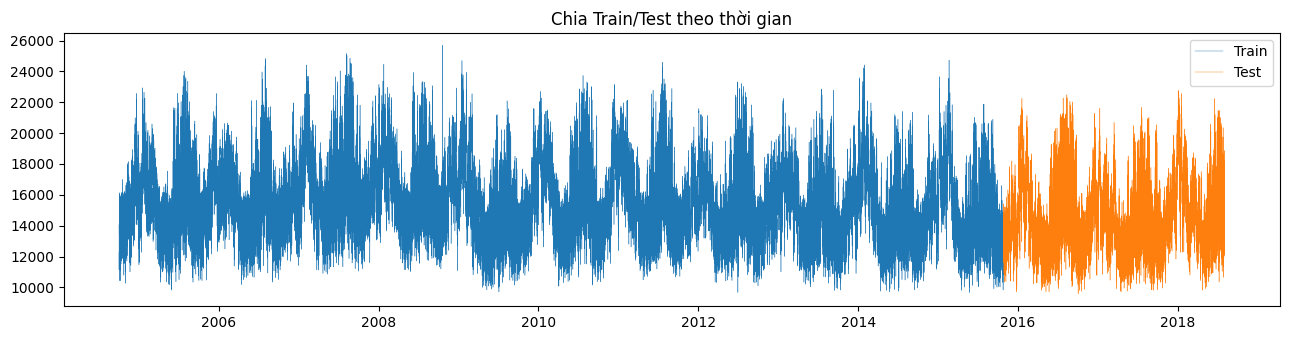

Phạm vi MW  Train: 9662.0 – 25695.0 | Test: 9581.0 – 22759.0
Trung bình  Train: 15695 | Test: 14716


In [5]:
X_train, X_test, y_train, y_test = time_train_test_split(X, y, test_size=0.2)
print(f'Train: {len(X_train)} dòng, {X_train.index.min()} → {X_train.index.max()}')
print(f'Test : {len(X_test)} dòng, {X_test.index.min()} → {X_test.index.max()}')
assert X_train.index.max() < X_test.index.min()
pd.concat([X_train, y_train], axis=1).to_csv(processed_dir / 'train_data.csv')
pd.concat([X_test, y_test], axis=1).to_csv(processed_dir / 'test_data.csv')

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(y_train.index, y_train.values, lw=0.3, label='Train'); ax.plot(y_test.index, y_test.values, lw=0.3, color='tab:orange', label='Test')
ax.set_title('Chia Train/Test theo thời gian'); ax.legend(); plt.tight_layout()
plt.savefig(fig_dir / 'step4_split.png', dpi=120, bbox_inches='tight'); plt.show()
print('Phạm vi MW  Train:', y_train.min(), '–', y_train.max(), '| Test:', y_test.min(), '–', y_test.max())
print('Trung bình  Train:', round(y_train.mean()), '| Test:', round(y_test.mean()))

**Nhận xét Bước 4:** Train gồm **97,018 dòng** (02/10/2004 → 27/10/2015 10:00), Test gồm **24,254 dòng** (27/10/2015 11:00 → 03/08/2018), Test nằm hoàn toàn sau Train. Lưu ý Test có **trung bình thấp hơn Train khoảng 6%** (14,716 so với 15,695 MW): nhu cầu điện có xu hướng giảm nhẹ theo thời gian nên Test không hoàn toàn cùng phân phối với Train. Test không vượt mức cao nhất của Train (22,759 so với 25,695 MW).

## Bước 5: Huấn luyện XGBoost Regressor

In [6]:
t0 = time.time()
xgb_model = train_xgboost(X_train, y_train)   # n_estimators=300, lr=0.05, max_depth=6, subsample=0.8, colsample=0.8
print(f'Huấn luyện xong sau {time.time() - t0:.1f}s | tham số chính:',
      {k: xgb_model.get_params()[k] for k in ['n_estimators', 'learning_rate', 'max_depth', 'subsample', 'colsample_bytree']})

Huấn luyện xong sau 4.5s | tham số chính: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8}


## Bước 6: Dự đoán và đánh giá

,MAE,RMSE,MAPE (%),R2
Naive (lag_1),407.577,525.536,2.807,0.954
Linear Regression,147.884,203.395,1.018,0.993
XGBoost,152.494,205.873,1.054,0.993


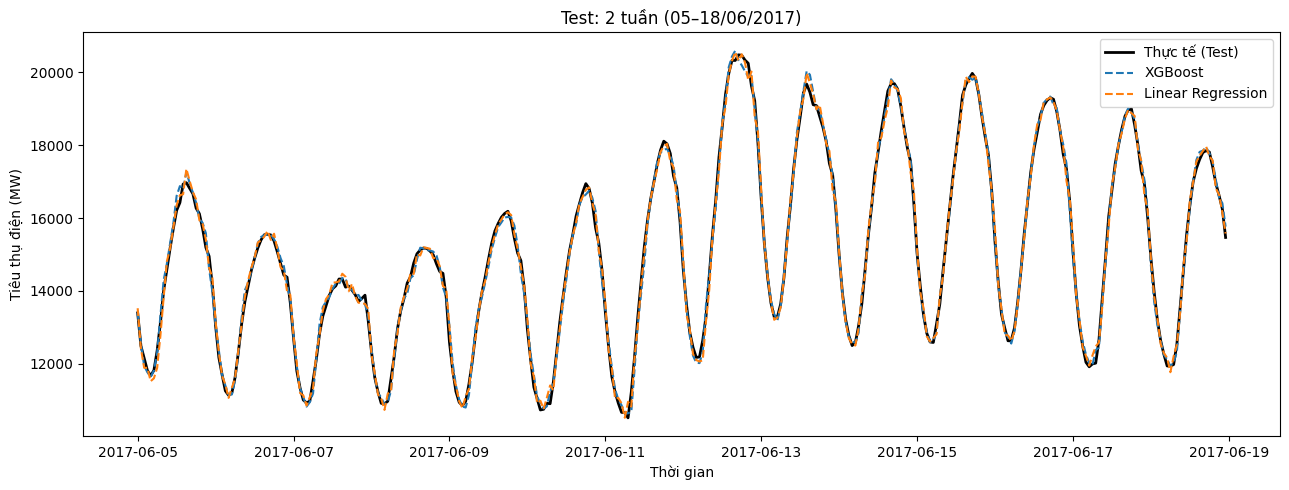

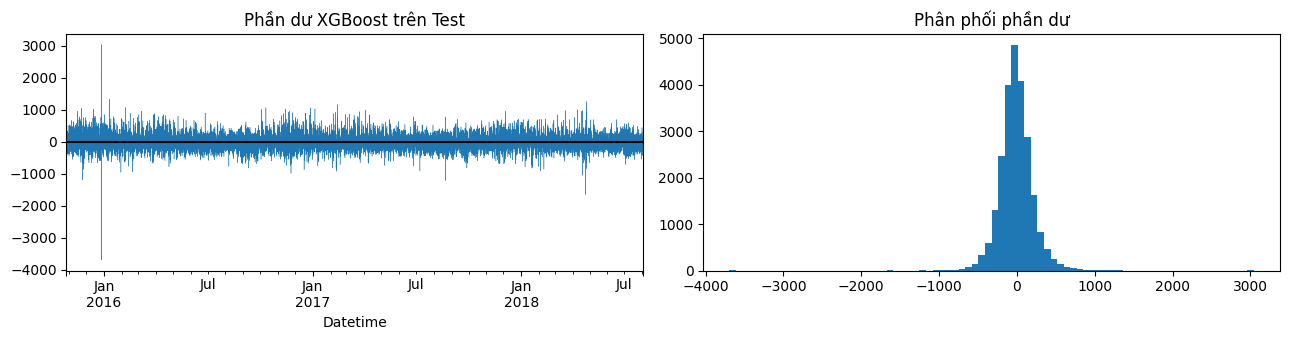

Phần dư: mean = -10.4 | std = 205.6
Tỷ lệ điểm Test vượt mức MW cao nhất của Train: 0.0 %


In [7]:
pred_xgb = xgb_model.predict(X_test)
lr_model = train_linear_regression(X_train, y_train)
pred_lr = lr_model.predict(X_test)
pred_naive = X_test['lag_1'].values   # baseline: dự đoán giờ sau = giờ trước

res = pd.DataFrame({'Naive (lag_1)': evaluate_regression(y_test, pred_naive),
                    'Linear Regression': evaluate_regression(y_test, pred_lr),
                    'XGBoost': evaluate_regression(y_test, pred_xgb)}).T
display(res.round(3))
plot_prediction(y_test, {'XGBoost': pred_xgb, 'Linear Regression': pred_lr}, start='2017-06-05', end='2017-06-18',
                title='Test: 2 tuần (05–18/06/2017)', save_path=str(fig_dir / 'step6_pred_2weeks.png'))
resid = y_test - pred_xgb
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
resid.plot(ax=ax[0], lw=0.3); ax[0].axhline(0, color='k'); ax[0].set_title('Phần dư XGBoost trên Test')
ax[1].hist(resid, bins=80); ax[1].set_title('Phân phối phần dư'); plt.tight_layout()
plt.savefig(fig_dir / 'step6_residuals.png', dpi=120, bbox_inches='tight'); plt.show()
print('Phần dư: mean =', round(resid.mean(), 1), '| std =', round(resid.std(), 1))
print('Tỷ lệ điểm Test vượt mức MW cao nhất của Train:', round((y_test > y_train.max()).mean() * 100, 2), '%')

**Nhận xét Bước 6:**

| Mô hình | MAE | RMSE | MAPE | R² |
|---|---|---|---|---|
| Naive (lag_1) | 407.6 | 525.5 | 2.81% | 0.954 |
| Linear Regression | 147.9 | 203.4 | 1.02% | 0.993 |
| XGBoost | 152.5 | 205.9 | 1.05% | 0.993 |

- XGBoost giảm RMSE khoảng **61%** so với baseline Naive; sai số trung bình khoảng 1.05% mức tiêu thụ.
- Phần dư có trung bình −10.4 MW (rất nhỏ so với độ lệch chuẩn 205.6), phân phối đối xứng quanh 0, nghĩa là không có thiên lệch hệ thống rõ rệt.
- **Điểm đáng chú ý:** với 24 lag, XGBoost mặc định **không tốt hơn** Linear Regression (RMSE 205.9 so với 203.4).
- Phần dư có một gai lớn quanh 27/12/2015: giờ 14:00 có giá trị 15,488 MW trong khi các giờ lân cận khoảng 12,400 MW, nhiều khả năng là điểm dữ liệu bất thường. Giữ nguyên, không xóa.
- Cần nhớ đây là dự báo **một bước** (từ lag_1 thật), nên đường dự báo bám sát đường thực tế gần như hoàn hảo trên biểu đồ; điều này dễ hơn nhiều so với dự báo xa (xem Nâng cao 2).

## Bước 7: Feature importance: lag nào ảnh hưởng mạnh nhất?

,feature,importance
0,lag_1,0.4704
1,lag_2,0.3183
2,lag_22,0.0652
3,lag_23,0.0426
4,lag_3,0.0182
5,lag_21,0.0120
6,lag_4,0.0096
7,lag_24,0.0096
8,lag_5,0.0069
9,lag_11,0.0057


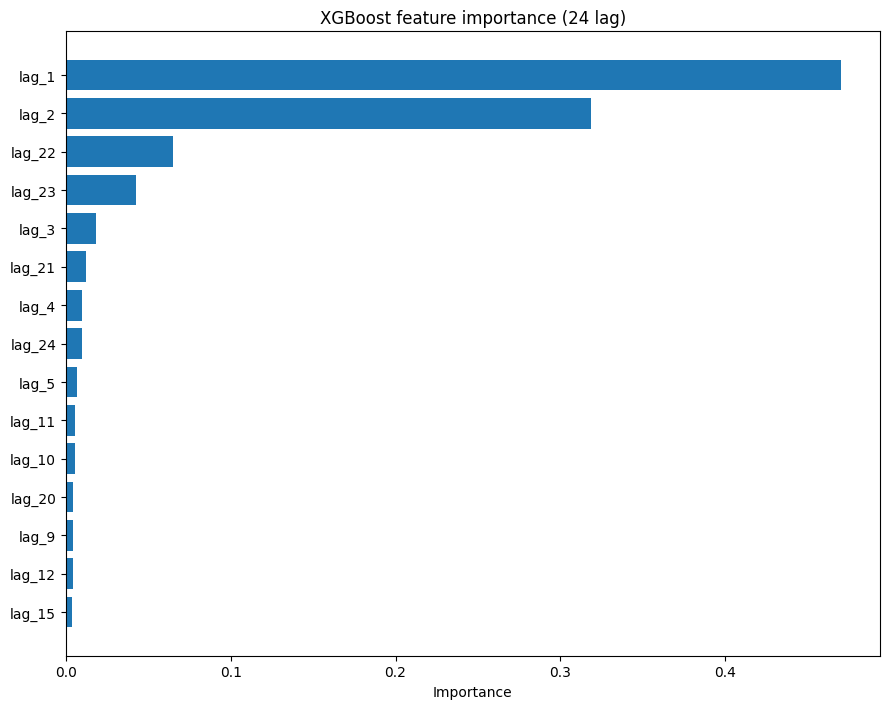

Tổng importance của lag_1 + lag_2: 0.789
Tổng importance của lag_22..lag_24 (cùng giờ hôm trước): 0.117


In [8]:
imp = get_feature_importance(xgb_model, X.columns)
display(imp.head(10).round(4))
plot_feature_importance(imp, top=15, title='XGBoost feature importance (24 lag)', save_path=str(fig_dir / 'step7_importance.png'))
print('Tổng importance của lag_1 + lag_2:', round(imp.set_index('feature').loc[['lag_1', 'lag_2'], 'importance'].sum(), 3))
print('Tổng importance của lag_22..lag_24 (cùng giờ hôm trước):', round(imp.set_index('feature').loc[['lag_22', 'lag_23', 'lag_24'], 'importance'].sum(), 3))

**Nhận xét Bước 7:**
- **lag_1 (47.0%) và lag_2 (31.8%)** chiếm tổng cộng **78.9%** importance: giá trị 1–2 giờ gần nhất quyết định phần lớn dự báo.
- Nhóm lag 21–24 (gần cùng giờ hôm trước) chiếm thêm khoảng 11.7% (lag_22: 6.5%, lag_23: 4.3%), thể hiện chu kỳ ngày.
- `lag_24` chỉ đạt khoảng 1% dù về mặt chu kỳ là lag "cùng giờ hôm qua": các lag 22, 23, 24 tương quan rất cao với nhau nên importance bị chia sẻ giữa chúng, vì vậy không nên đọc từng lag riêng lẻ mà nên đọc theo nhóm.
- Random Forest cho cùng kết luận (lag_1 55%, lag_2 23%, lag_24 10%).

# Bài tập nâng cao

## Nâng cao 1: Rolling mean / rolling std

,MAE,RMSE,MAPE (%),R2
XGBoost (24 lag),152.542,205.933,1.054,0.993
XGBoost (24 lag + rolling),151.444,203.720,1.046,0.993
Linear Reg. (24 lag),147.902,203.404,1.018,0.993
Linear Reg. (24 lag + rolling),147.474,203.048,1.015,0.993


Số dòng Test dùng chung: 24226 (Test gốc có 24254 dòng)


,feature,importance
0,lag_1,0.4607
1,lag_2,0.2135
2,lag_23,0.1533
3,lag_3,0.0475
4,lag_22,0.0377
5,lag_21,0.0147
6,lag_4,0.0094
7,lag_11,0.0060


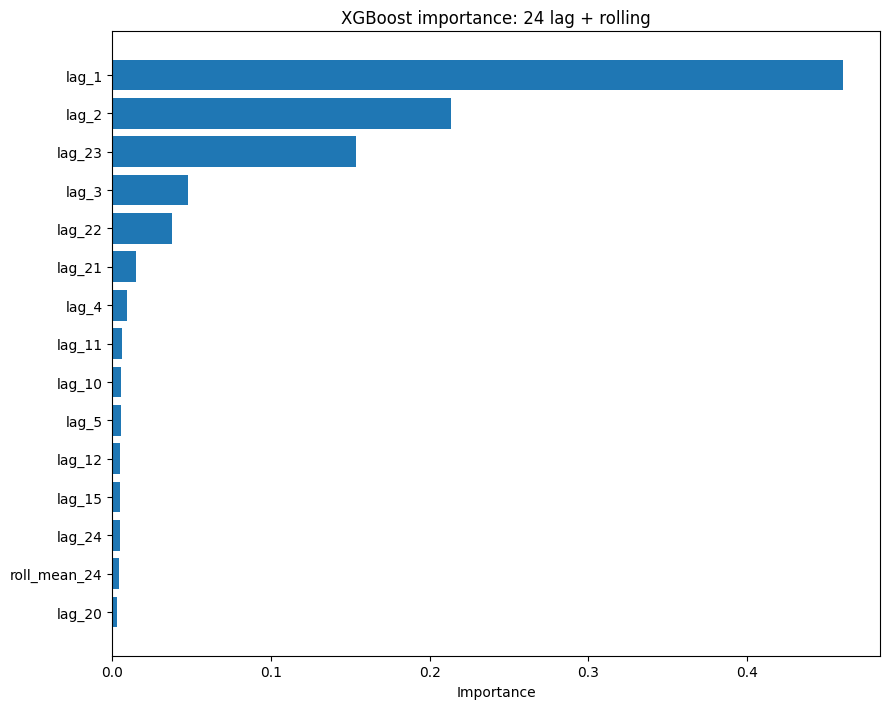

Tổng importance của 4 đặc trưng rolling: 0.008


,feature,importance
13,roll_mean_24,0.0043
19,roll_std_24,0.0019
22,roll_std_168,0.0017
27,roll_mean_168,0.0005


In [9]:
df_roll = add_rolling_features(make_lag_features(series, N_LAGS), series, windows=(24, 168))
Xr, yr = split_X_y(df_roll)
Xr_tr, Xr_te, yr_tr, yr_te = time_train_test_split(Xr, yr, 0.2)
xgb_roll = train_xgboost(Xr_tr, yr_tr)
lr_roll = train_linear_regression(Xr_tr, yr_tr)
common = yr_te.index   # cùng một tập Test cho cả 4 mô hình (rolling 168h làm điểm cắt 80/20 dịch ~28 giờ)
pred_xgb_s = pd.Series(pred_xgb, index=y_test.index).loc[common]
pred_lr_s = pd.Series(pred_lr, index=y_test.index).loc[common]
res_roll = pd.DataFrame({'XGBoost (24 lag)': evaluate_regression(yr_te, pred_xgb_s),
                         'XGBoost (24 lag + rolling)': evaluate_regression(yr_te, xgb_roll.predict(Xr_te)),
                         'Linear Reg. (24 lag)': evaluate_regression(yr_te, pred_lr_s),
                         'Linear Reg. (24 lag + rolling)': evaluate_regression(yr_te, lr_roll.predict(Xr_te))}).T
display(res_roll.round(3))
print('Số dòng Test dùng chung:', len(common), '(Test gốc có', len(y_test), 'dòng)')
imp_r = get_feature_importance(xgb_roll, Xr.columns)
display(imp_r.head(8).round(4))
plot_feature_importance(imp_r, top=15, title='XGBoost importance: 24 lag + rolling', save_path=str(fig_dir / 'adv1_importance.png'))
roll_imp = imp_r[imp_r['feature'].str.startswith('roll')]
print('Tổng importance của 4 đặc trưng rolling:', round(roll_imp['importance'].sum(), 3))
display(roll_imp.round(4))

**Nhận xét Nâng cao 1 (rolling mean/std, cửa sổ 24 và 168 giờ, đã `shift(1)` chống rò rỉ):**
- Đánh giá trên cùng 24,226 dòng Test: XGBoost RMSE **205.9 → 203.7** (−1.1%), Linear Regression 203.4 → 203.0. Cải thiện **rất nhỏ**.
- Bốn đặc trưng rolling chỉ chiếm **0.8%** tổng importance (cao nhất là `roll_mean_24` 0.4%). Lý do hợp lý: trung bình 24 giờ gần như là hàm tuyến tính của 24 lag đã có, còn cửa sổ 168 giờ chỉ thêm thông tin tuần rất ít khi đã có lag_1, lag_2.
- Kết luận: với bài toán một bước này, rolling không đáng kể. Rolling có thể hữu ích hơn khi dự báo xa hoặc khi chuỗi nhiễu hơn (chưa kiểm tra).

## Nâng cao 2: Dự báo multi-step (H = 24 giờ)

Train multi-step: (96975, 24) | Test: (24250, 24)


Huấn luyện 24 mô hình DIRECT: 44s


,RMSE recursive,RMSE direct,RMSE seasonal naive,MAPE% recursive,MAPE% direct
1,205.91,242.54,1221.19,1.05,1.28
2,360.74,418.12,1221.12,1.87,2.24
3,490.34,528.71,1221.07,2.56,2.86
6,802.32,760.70,1220.93,4.19,4.10
12,1072.85,992.94,1220.81,5.60,5.38
18,1166.10,1103.54,1220.96,6.07,6.02
24,1212.24,1160.46,1221.02,6.32,6.33


Trung bình 24 bước: RMSE recursive = 962.7 | direct = 914.9 | seasonal naive = 1220.9


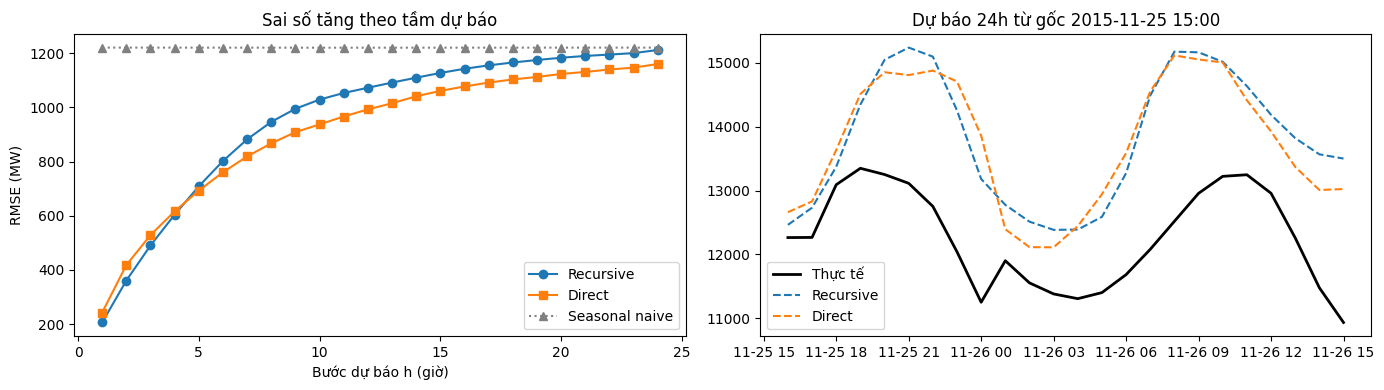

In [10]:
H = 24
ms = make_multistep_targets(series, N_LAGS, H)
Xm = ms[[f'lag_{k}' for k in range(1, N_LAGS + 1)]]
Ym = ms[[f'target_h{h}' for h in range(1, H + 1)]]
Xm_tr, Xm_te, Ym_tr, Ym_te = time_train_test_split(Xm, Ym, 0.2)
# Bỏ H dòng cuối của Train: nhãn của chúng (t+1..t+H) đã rơi vào giai đoạn Test -> tránh rò rỉ
Xm_tr, Ym_tr = Xm_tr.iloc[:-H], Ym_tr.iloc[:-H]
print('Train multi-step:', Xm_tr.shape, '| Test:', Xm_te.shape)

t0 = time.time()
direct_models = train_direct_models(Xm_tr, Ym_tr, n_estimators=100)   # 24 mô hình, mỗi bước h một mô hình
print(f'Huấn luyện {len(direct_models)} mô hình DIRECT: {time.time() - t0:.0f}s')
pred_direct = direct_forecast(direct_models, Xm_te)
pred_recur = recursive_forecast(xgb_model, Xm_te, H)   # tái dùng mô hình một bước ở Bước 5
Y_true = Ym_te.to_numpy()
# Baseline seasonal naive: dự đoán y_{t+h} = y_{t+h-24} (cùng giờ hôm trước) = lag_{25-h}
pred_snaive = np.column_stack([Xm_te[f'lag_{25 - h}'].to_numpy() for h in range(1, H + 1)])
m_snaive = multistep_metrics_by_horizon(Y_true, pred_snaive)
m_direct = multistep_metrics_by_horizon(Y_true, pred_direct)
m_recur = multistep_metrics_by_horizon(Y_true, pred_recur)
pick = [1, 2, 3, 6, 12, 18, 24]
display(pd.DataFrame({'RMSE recursive': m_recur.loc[pick, 'RMSE'], 'RMSE direct': m_direct.loc[pick, 'RMSE'], 'RMSE seasonal naive': m_snaive.loc[pick, 'RMSE'],
                      'MAPE% recursive': m_recur.loc[pick, 'MAPE (%)'], 'MAPE% direct': m_direct.loc[pick, 'MAPE (%)']}).round(2))
print('Trung bình 24 bước: RMSE recursive =', round(m_recur['RMSE'].mean(), 1), '| direct =', round(m_direct['RMSE'].mean(), 1), '| seasonal naive =', round(m_snaive['RMSE'].mean(), 1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(m_recur.index, m_recur['RMSE'], 'o-', label='Recursive'); ax[0].plot(m_direct.index, m_direct['RMSE'], 's-', label='Direct'); ax[0].plot(m_snaive.index, m_snaive['RMSE'], '^:', color='gray', label='Seasonal naive')
ax[0].set_xlabel('Bước dự báo h (giờ)'); ax[0].set_ylabel('RMSE (MW)'); ax[0].set_title('Sai số tăng theo tầm dự báo'); ax[0].legend()
i0 = 24 * 30   # một thời điểm gốc bất kỳ trong Test
origin = Xm_te.index[i0]
hrs = pd.date_range(origin + pd.Timedelta(hours=1), periods=H, freq='h')
ax[1].plot(hrs, Y_true[i0], 'k', lw=2, label='Thực tế'); ax[1].plot(hrs, pred_recur[i0], '--', label='Recursive'); ax[1].plot(hrs, pred_direct[i0], '--', label='Direct')
ax[1].set_title(f'Dự báo 24h từ gốc {origin:%Y-%m-%d %H:%M}'); ax[1].legend(); plt.tight_layout()
plt.savefig(fig_dir / 'adv2_multistep.png', dpi=120, bbox_inches='tight'); plt.show()

**Nhận xét Nâng cao 2 (multi-step, H = 24 giờ):** so sánh *recursive* (dùng mô hình một bước, đưa dự báo vào làm lag), *direct* (24 mô hình riêng) và baseline *seasonal naive* (lấy giá trị cùng giờ hôm qua).

| Bước h | Recursive | Direct | Seasonal naive |
|---|---|---|---|
| 1 | 205.9 | 242.5 | 1,221 |
| 6 | 802.3 | 760.7 | 1,221 |
| 12 | 1,072.9 | 992.9 | 1,221 |
| 24 | 1,212.2 | 1,160.5 | 1,221 |
| Trung bình 24 bước | 962.7 | 914.9 | 1,220.9 |

- Sai số **tăng nhanh theo tầm dự báo** (recursive tăng gấp khoảng 5.9 lần từ h=1 đến h=24), vì dự báo xa mất thông tin về dữ liệu thật và recursive còn tích lũy sai số.
- Recursive tốt hơn ở 1–3 giờ đầu, direct tốt hơn từ khoảng h=6 trở đi; trung bình direct thấp hơn khoảng 5%. Lưu ý các mô hình direct dùng `n_estimators=100` (để chạy nhanh) còn mô hình recursive dùng 300, nên phần chênh ở h=1 một phần do cấu hình khác nhau chứ không chỉ do phương pháp.
- Seasonal naive có RMSE gần như hằng số (~1,221) vì sai số luôn là chênh lệch 24 giờ. **Ở h=24, mô hình ML chỉ hơn baseline này khoảng 1–5%**: mô hình chỉ thật sự có giá trị ở tầm ngắn; ở tầm một ngày thì phải thêm đặc trưng khác (giờ trong ngày, thứ trong tuần, thời tiết) mới có lợi thế rõ.

## Nâng cao 3: Tune hyperparameter bằng TimeSeriesSplit

In [11]:
param_dist = {'n_estimators': [100, 200, 300], 'max_depth': [3, 4, 6, 8], 'learning_rate': [0.03, 0.05, 0.1],
              'subsample': [0.7, 0.8, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 5, 10]}
t0 = time.time()
search = tune_xgboost_timeseries(X_train, y_train, param_dist, n_splits=3, n_iter=8)   # chỉ dùng Train
print(f'Tune xong sau {time.time() - t0:.0f}s | best CV RMSE = {-search.best_score_:.1f}')
print('Siêu tham số tốt nhất:', search.best_params_)
pd.set_option('display.max_colwidth', None)
cv = pd.DataFrame(search.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score')
cv['CV RMSE'] = -cv['mean_test_score']
display(cv[['rank_test_score', 'CV RMSE', 'std_test_score', 'params']].round(1))

xgb_tuned = search.best_estimator_
res_tune = pd.DataFrame({'XGBoost mặc định': evaluate_regression(y_test, pred_xgb),
                         'XGBoost đã tune': evaluate_regression(y_test, xgb_tuned.predict(X_test))}).T
display(res_tune.round(3))

Tune xong sau 67s | best CV RMSE = 209.1
Siêu tham số tốt nhất: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


,rank_test_score,CV RMSE,std_test_score,params
2,1,209.1,17.1,"{'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 1.0}"
4,2,229.5,19.7,"{'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.6}"
0,3,243.3,18.8,"{'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.6}"
5,4,256.0,16.5,"{'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6}"
3,5,269.1,18.6,"{'subsample': 0.7, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.6}"
6,6,275.4,13.6,"{'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0}"
1,7,343.5,12.9,"{'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}"
7,8,539.3,15.6,"{'subsample': 1.0, 'n_estimators': 100, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}"


,MAE,RMSE,MAPE (%),R2
XGBoost mặc định,152.494,205.873,1.054,0.993
XGBoost đã tune,138.508,189.042,0.955,0.994


**Nhận xét Nâng cao 3 (RandomizedSearchCV + TimeSeriesSplit 3 fold, 8 tổ hợp, chỉ dùng Train):**
- Tổ hợp tốt nhất: `n_estimators=200, max_depth=8, learning_rate=0.05, subsample=1.0, colsample_bytree=1.0, min_child_weight=10`, với CV RMSE 209.1.
- CV RMSE giữa các tổ hợp chênh rất lớn (209 đến 539), cho thấy siêu tham số ảnh hưởng mạnh; tổ hợp kém nhất là cây nông (`max_depth=3`) với ít cây.
- Trên Test, mô hình đã tune đạt RMSE **189.0** (so với 205.9, giảm 8.2%), MAE 152.5 → 138.5, MAPE 1.05% → 0.96%. Test được dùng đúng một lần để đánh giá sau khi tune.
- RMSE Test (189) thấp hơn CV RMSE (209) vì các fold của TimeSeriesSplit huấn luyện trên ít dữ liệu hơn (25%/50%/75% Train). Chỉ thử 8 tổ hợp nên có thể còn tìm được cấu hình tốt hơn.

## Nâng cao 4: So sánh với Random Forest

,MAE,RMSE,MAPE (%),R2,Thời gian fit (s)
Linear Regression,147.884,203.395,1.018,0.993,NaN
Random Forest,157.067,211.870,1.081,0.992,82.442
XGBoost,152.494,205.873,1.054,0.993,4.266
XGBoost đã tune,138.508,189.042,0.955,0.994,NaN


,feature (XGB),importance (XGB),feature (RF),importance (RF)
0,lag_1,0.470,lag_1,0.550
1,lag_2,0.318,lag_2,0.230
2,lag_22,0.065,lag_24,0.103
3,lag_23,0.043,lag_23,0.055
4,lag_3,0.018,lag_3,0.018


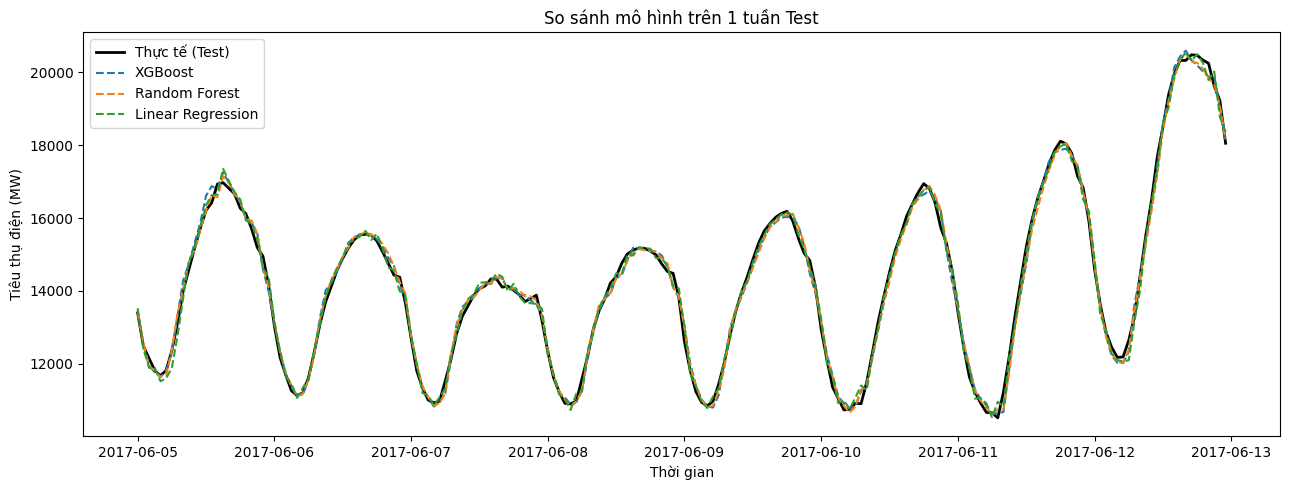

In [12]:
t0 = time.time(); rf_model = train_random_forest(X_train, y_train); t_rf = time.time() - t0
t0 = time.time(); _ = train_xgboost(X_train, y_train); t_x = time.time() - t0
pred_rf = rf_model.predict(X_test)
res_rf = pd.DataFrame({'Linear Regression': evaluate_regression(y_test, pred_lr),
                       'Random Forest': evaluate_regression(y_test, pred_rf),
                       'XGBoost': evaluate_regression(y_test, pred_xgb),
                       'XGBoost đã tune': evaluate_regression(y_test, xgb_tuned.predict(X_test))}).T
res_rf['Thời gian fit (s)'] = [np.nan, t_rf, t_x, np.nan]
display(res_rf.round(3))
imp_rf = get_feature_importance(rf_model, X.columns)
display(pd.concat([imp.head(5).add_suffix(' (XGB)'), imp_rf.head(5).add_suffix(' (RF)')], axis=1).round(3))
plot_prediction(y_test, {'XGBoost': pred_xgb, 'Random Forest': pred_rf, 'Linear Regression': pred_lr}, start='2017-06-05', end='2017-06-12',
                title='So sánh mô hình trên 1 tuần Test', save_path=str(fig_dir / 'adv4_compare.png'))

**Nhận xét Nâng cao 4 (Random Forest, tham số mặc định của hàm: 100 cây, `max_depth=12`, chưa tune):**
- RMSE: RF **211.9** > XGBoost 205.9 > Linear Regression 203.4 > XGBoost đã tune 189.0. XGBoost nhỉnh hơn RF khoảng 3% và tune xong thì hơn khoảng 11%.
- RF huấn luyện chậm hơn rất nhiều (82s so với 4.3s, khoảng 19 lần) trên máy này.
- Hai mô hình cho cùng nhận định về lag: lag_1 và lag_2 chiếm phần lớn importance. Khác biệt nhỏ ở chỗ lag 22/23/24 nào được chọn là do chúng tương quan cao với nhau.
- Lưu ý RF chưa được tune còn XGBoost đã tune, nên phần chênh 11% không hoàn toàn công bằng.

# Trả lời câu hỏi

## Câu 1: So sánh XGBoost với Linear Regression

So sánh ở nhiều số lag khác nhau (cũng là dữ liệu cho Câu 2).

In [13]:
lag_grid = [1, 2, 3, 6, 12, 24, 48, 168]
rows = []
for k in lag_grid:
    d = make_lag_features(series, k)
    Xk, yk = split_X_y(d); a, b, c, e = time_train_test_split(Xk, yk, 0.2)
    t0 = time.time(); mx = train_xgboost(a, c); tx = time.time() - t0
    t0 = time.time(); ml = train_linear_regression(a, c); tl = time.time() - t0
    ex, el = evaluate_regression(e, mx.predict(b)), evaluate_regression(e, ml.predict(b))
    rows.append({'k': k, 'RMSE XGB': ex['RMSE'], 'RMSE LR': el['RMSE'], 'MAPE% XGB': ex['MAPE (%)'], 'MAPE% LR': el['MAPE (%)'],
                 'MAE XGB': ex['MAE'], 'MAE LR': el['MAE'], 'giây XGB': tx, 'giây LR': tl})
lag_tab = pd.DataFrame(rows).set_index('k')
display(lag_tab.round(2))

,RMSE XGB,RMSE LR,MAPE% XGB,MAPE% LR,MAE XGB,MAE LR,giây XGB,giây LR
k,,,,,,,,
1,524.02,523.12,2.83,2.82,409.04,407.62,1.15,0.00
2,608.97,290.33,3.33,1.46,480.03,212.48,1.53,0.01
3,303.73,279.80,1.58,1.40,228.16,203.44,1.35,0.01
6,276.57,276.11,1.41,1.37,203.34,200.10,1.64,0.01
12,244.51,272.27,1.22,1.35,176.79,197.78,2.17,0.02
24,205.87,203.40,1.05,1.02,152.49,147.88,4.01,0.05
48,192.18,172.92,1.00,0.85,144.02,122.89,7.65,0.14
168,189.20,149.54,0.99,0.76,143.09,109.17,28.46,0.91


**Trả lời Câu 1: XGBoost so với Linear Regression**

| Số lag k | RMSE XGBoost | RMSE Linear Reg. | Ghi chú |
|---|---|---|---|
| 1 | 524.0 | 523.1 | cả hai ≈ Naive (525.5) |
| 2 | 609.0 | 290.3 | XGBoost **tệ hơn cả Naive** |
| 6 | 276.6 | 276.1 | ngang nhau |
| 12 | 244.5 | 272.3 | XGBoost tốt hơn 10% |
| 24 | 205.9 | 203.4 | ngang nhau |
| 168 | 189.2 | 149.5 | Linear Reg. tốt hơn 21% |

- Linear Regression **không thua XGBoost** trên bài toán này; nó chỉ thua sau khi XGBoost được tune (189.0 so với 203.4, hơn 7%).
- Linear Regression huấn luyện gần như tức thì (0.91s ở k=168, XGBoost 28.5s), dễ diễn giải (hệ số từng lag) và tận dụng tốt nhiều lag, có thể vì nhu cầu điện phụ thuộc gần tuyến tính vào quá khứ gần (chưa kiểm chứng riêng).
- XGBoost có lợi thế khi quan hệ **phi tuyến**, ví dụ ở k=12 nó hơn Linear Regression 10%. Có thể XGBoost suy ra giờ trong ngày từ hình dạng của các lag (chưa kiểm chứng).
- Ở k=2, XGBoost kém hẳn (609 so với 290). Giải thích khả dĩ: cây quyết định chia giá trị thành các khoảng cố định nên khó biểu diễn đúng quan hệ "xu hướng" như y ≈ 2·lag_1 − lag_2 mà hồi quy tuyến tính bắt được trực tiếp (chưa kiểm chứng riêng).
- Hạn chế: XGBoost ở đây dùng tham số mặc định cho mọi k; không có đặc trưng lịch (giờ, thứ, ngày lễ) cho cả hai mô hình.

## Câu 2: Điều gì xảy ra khi tăng số lag k?

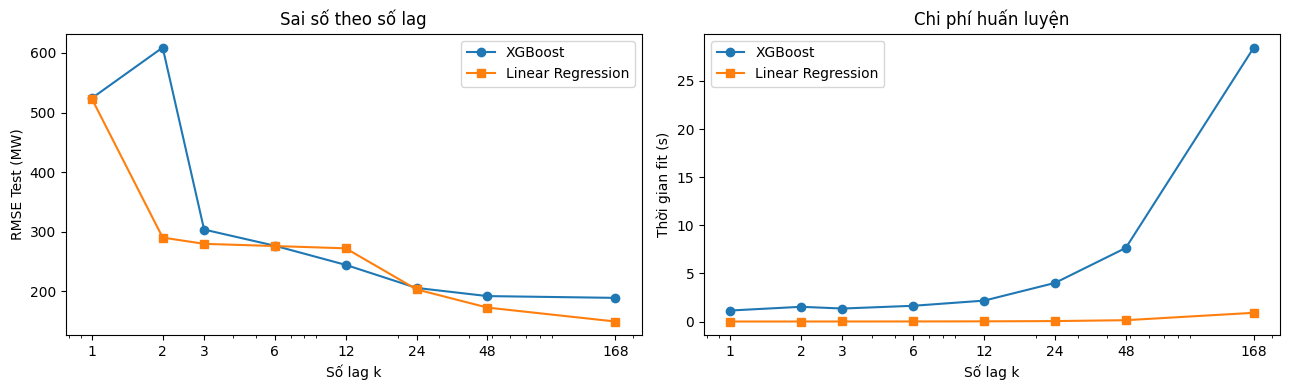

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(lag_tab.index, lag_tab['RMSE XGB'], 'o-', label='XGBoost'); ax[0].plot(lag_tab.index, lag_tab['RMSE LR'], 's-', label='Linear Regression')
ax[0].set_xscale('log'); ax[0].set_xticks(lag_grid); ax[0].set_xticklabels(lag_grid); ax[0].set_xlabel('Số lag k'); ax[0].set_ylabel('RMSE Test (MW)'); ax[0].legend(); ax[0].set_title('Sai số theo số lag')
ax[1].plot(lag_tab.index, lag_tab['giây XGB'], 'o-', label='XGBoost'); ax[1].plot(lag_tab.index, lag_tab['giây LR'], 's-', label='Linear Regression')
ax[1].set_xscale('log'); ax[1].set_xticks(lag_grid); ax[1].set_xticklabels(lag_grid); ax[1].set_xlabel('Số lag k'); ax[1].set_ylabel('Thời gian fit (s)'); ax[1].legend(); ax[1].set_title('Chi phí huấn luyện')
plt.tight_layout(); plt.savefig(fig_dir / 'q2_lag_sweep.png', dpi=120, bbox_inches='tight'); plt.show()

**Trả lời Câu 2: Điều gì xảy ra khi tăng số lag k?**
- **Sai số giảm mạnh lúc đầu rồi chậm lại:** RMSE giảm từ ~524 (k=1) xuống ~205 (k=24), vì k=24 chứa đủ một chu kỳ ngày. Từ k=24 lên 48 và 168, Linear Regression tiếp tục giảm (203 → 173 → 150) còn XGBoost gần như đi ngang (206 → 192 → 189), trong khi chi phí huấn luyện XGBoost tăng khoảng 25 lần (1.15s → 28.5s).
- **Số lag nên khớp với chu kỳ của dữ liệu:** 24 cho chu kỳ ngày, 168 cho chu kỳ tuần.
- **Cái giá của nhiều lag:** thêm đặc trưng ít thông tin, tăng thời gian tính và nguy cơ overfit với mô hình cây, mất thêm k dòng dữ liệu đầu, đa cộng tuyến giữa các lag (ảnh hưởng cách đọc importance).
- Vì bảng này dùng XGBoost chưa tune, việc nó đi ngang một phần có thể do tham số chưa phù hợp: XGBoost đã tune ở k=24 (189.0) đã bằng XGBoost chưa tune ở k=168 (189.2).
- Các Test ở mỗi k lệch nhau không quá vài chục giờ do mất k dòng đầu, không ảnh hưởng đáng kể.

## Câu 3: Khi nào XGBoost phù hợp hơn ARIMA?

**Trả lời Câu 3: Khi nào XGBoost phù hợp hơn ARIMA?** *(trả lời bằng lý thuyết và các kết quả ở trên; chưa chạy ARIMA trên dữ liệu AEP, vì 121,000 điểm theo giờ với chu kỳ 24 và 168 rất nặng cho SARIMA).*

**XGBoost thường phù hợp hơn khi:**
- Có **biến ngoại sinh** (thời tiết, ngày lễ, giờ, thứ) vì XGBoost nhận thêm cột dễ dàng, còn ARIMA thuần túy chỉ dùng quá khứ của chính chuỗi.
- Quan hệ **phi tuyến** hoặc có tương tác giữa các đặc trưng.
- **Dữ liệu lớn** hoặc nhiều chuỗi cùng lúc, và cần mô hình chung; không muốn kiểm định tính dừng và chọn (p,d,q) cho từng chuỗi.
- **Chu kỳ dài** (ví dụ s=168 theo giờ) mà SARIMA xử lý kém hoặc rất chậm.

**ARIMA phù hợp hơn khi:**
- Chuỗi **ngắn** (vài chục đến vài trăm điểm), như AirPassengers ở Lab 2; ML dễ overfit khi ít dữ liệu.
- Cần **khoảng tin cậy** dự báo và mô hình có cơ sở thống kê, diễn giải được.
- Chuỗi có **xu hướng rõ**: mô hình cây không ngoại suy ra ngoài miền giá trị đã thấy.

**Từ kết quả lab này:** ARIMA về bản chất là mô hình tuyến tính của quá khứ, nên đối tượng sát nhất là Linear Regression trên lag. Nó ngang XGBoost mặc định (203.4 so với 205.9) và chỉ thua XGBoost đã tune khoảng 7%. Vì vậy XGBoost không tự động tốt hơn; lợi thế thật nằm ở khả năng thêm đặc trưng và phi tuyến, và cần tune.

## Tổng hợp kết quả trên tập Test

In [15]:
summary = pd.DataFrame({'Naive (lag_1)': evaluate_regression(y_test, pred_naive),
                        'Linear Regression (24 lag)': evaluate_regression(y_test, pred_lr),
                        'Random Forest (24 lag)': evaluate_regression(y_test, pred_rf),
                        'XGBoost (24 lag)': evaluate_regression(y_test, pred_xgb),
                        'XGBoost đã tune (24 lag)': evaluate_regression(y_test, xgb_tuned.predict(X_test)),
                        'XGBoost (24 lag + rolling) *': evaluate_regression(yr_te, xgb_roll.predict(Xr_te))}).T
display(summary.round(3))
print('* Test rút gọn còn', len(yr_te), 'dòng (do rolling 168h); các dòng còn lại dùng', len(y_test), 'dòng.')

,MAE,RMSE,MAPE (%),R2
Naive (lag_1),407.577,525.536,2.807,0.954
Linear Regression (24 lag),147.884,203.395,1.018,0.993
Random Forest (24 lag),157.067,211.870,1.081,0.992
XGBoost (24 lag),152.494,205.873,1.054,0.993
XGBoost đã tune (24 lag),138.508,189.042,0.955,0.994
XGBoost (24 lag + rolling) *,151.444,203.720,1.046,0.993


* Test rút gọn còn 24226 dòng (do rolling 168h); các dòng còn lại dùng 24254 dòng.


**Kết luận chung:**
- **Tốt nhất trên Test:** XGBoost đã tune (RMSE 189.0, MAPE 0.96%), tiếp theo là Linear Regression (203.4), XGBoost mặc định (205.9) và Random Forest (211.9); tất cả giảm khoảng 60 đến 64% sai số so với Naive (525.5).
- Cả bốn mô hình đều chủ yếu dựa vào 1–2 giờ gần nhất (lag_1 + lag_2 ≈ 79% importance).
- Rolling mean/std gần như không giúp ích; dự báo xa 24 giờ chỉ hơn baseline "cùng giờ hôm qua" khoảng 1–5%.
- Cần thận trọng khi diễn giải: kết quả là dự báo một bước trên một lần chia Train/Test, chưa có đặc trưng lịch/thời tiết, RF chưa tune, và điểm dữ liệu bất thường 27/12/2015 được giữ nguyên.
- (*) dòng rolling được đánh giá trên Test rút gọn 24,226 dòng.